# 11장 · 학습 — 무작위 가중치가 똑똑해지기까지 📉

웹 챕터 **"학습"** 과 짝을 이루는 실습입니다.
**손실(크로스 엔트로피)** 과 **경사하강**을 직접 계산하고, 작은 예측기를 실제로 **학습**시켜 봅니다.

준비물: `pip install -r requirements.txt`

> 🤖 **AI 튜터**: 아래 셀을 실행하면 웹앱처럼 화면 오른쪽 아래에 🤖 버튼이 생깁니다.
> 버튼을 누르면 채팅창이 열리고, 어디를 스크롤해도 그 자리에 떠 있어요. 막히면 언제든 질문하세요.
> (로컬 Ollama 필요. 꺼져 있으면 켜는 방법이 안내되고, 튜터 없이도 학습에는 지장 없습니다.)

In [ ]:
# 🤖 AI 튜터 — 실행하면 오른쪽 아래에 🤖 버튼이 떠요
from tutor import chat

chat('ch11')

## 1. 손실 = 얼마나 틀렸나 (크로스 엔트로피)

다음 단어 예측의 손실은 **정답 단어에 준 확률** p 로 정합니다: $\text{손실} = -\ln(p)$.
정답을 확신할수록(p→1) 손실은 0, 놓칠수록(p→0) 손실은 커집니다.

> ln 은 **로그**라는 함수인데(정식 소개는 2부 7장), 지금은 "p=1 이면 0, p 가 작아질수록
> 확 커지는 벌점 변환"으로만 읽어도 충분해요. 아래 표가 그 모양입니다.

In [1]:
import numpy as np

for p in [0.99, 0.5, 0.1, 0.01]:
    print(f'정답 확률 {p:>4}: 손실 {-np.log(p):.3f}')
print('정답 확률 1.0 : 손실', -np.log(1.0), '(완벽)')

정답 확률 0.99: 손실 0.010
정답 확률  0.5: 손실 0.693
정답 확률  0.1: 손실 2.303
정답 확률 0.01: 손실 4.605
정답 확률 1.0 : 손실 -0.0 (완벽)


## 2. 경사하강: 손실 골짜기로 내려가기

손실 곡선 $f(w)=(w-2)^2$ 위에서, 기울기 $f'(w)=2(w-2)$ 의 **반대 방향**으로 조금씩 이동합니다.
$$w \leftarrow w - \text{학습률} \times \text{기울기}$$

In [2]:
def f(w):    return (w - 2)**2
def grad(w): return 2*(w - 2)

w, lr = 4.5, 0.1     # 시작 가중치, 학습률
for step in range(1, 21):
    w = w - lr * grad(w)
    if step % 4 == 0:
        print(f'{step:2d}걸음: w={w:.3f}, 손실={f(w):.4f}')
print('→ 최소(w=2)에 가까워졌습니다')

 4걸음: w=3.024, 손실=1.0486
 8걸음: w=2.419, 손실=0.1759
12걸음: w=2.172, 손실=0.0295
16걸음: w=2.070, 손실=0.0050
20걸음: w=2.029, 손실=0.0008
→ 최소(w=2)에 가까워졌습니다


## 3. 학습률이 너무 크면? 발산!

걸음이 너무 크면 골짜기를 지나쳐 튕겨 나갑니다. (웹 실험실에서 본 그 발산)

In [3]:
w, lr = 4.5, 1.05     # 학습률 > 1
for step in range(1, 7):
    w = w - lr * grad(w)
    print(f'{step}걸음: w={w:8.2f}, 손실={f(w):10.2f}')
print('→ 점점 커짐 = 발산 💥')

1걸음: w=   -0.75, 손실=      7.56
2걸음: w=    5.03, 손실=      9.15
3걸음: w=   -1.33, 손실=     11.07
4걸음: w=    5.66, 손실=     13.40
5걸음: w=   -2.03, 손실=     16.21
6걸음: w=    6.43, 손실=     19.62
→ 점점 커짐 = 발산 💥


## 4. 작은 예측기를 실제로 학습시키기

단어 3개짜리 아주 작은 분류 문제로 **진짜 학습 루프**를 돌립니다:
점수(logits) → 소프트맥스 → 크로스 엔트로피 손실 → 경사하강. 손실이 내려가는 걸 확인하세요.

In [4]:
rng = np.random.default_rng(0)
V = 3                       # 후보 단어 3개
target = 0                  # 정답은 0번 단어
logits = rng.normal(0, 1, V)   # 무작위 시작 점수

def softmax(z):
    z = z - z.max(); e = np.exp(z); return e / e.sum()

lr = 0.5
for step in range(1, 31):
    p = softmax(logits)
    loss = -np.log(p[target])
    # 소프트맥스+크로스엔트로피의 기울기: p - onehot(target)
    g = p.copy(); g[target] -= 1
    logits -= lr * g                 # 경사하강
    if step % 6 == 0 or step == 1:
        print(f'{step:2d}걸음: 손실={loss:.3f}, 정답확률={p[target]*100:4.1f}%')
print('학습 후 정답 확률:', f'{softmax(logits)[target]*100:.1f}%')

 1걸음: 손실=1.237, 정답확률=29.0%
 6걸음: 손실=0.311, 정답확률=73.3%
12걸음: 손실=0.140, 정답확률=87.0%
18걸음: 손실=0.088, 정답확률=91.6%
24걸음: 손실=0.064, 정답확률=93.8%
30걸음: 손실=0.050, 정답확률=95.1%
학습 후 정답 확률: 95.3%


## 5. 손실 곡선 그래프

학습이 진행되며 손실이 내려가는 전형적인 모습입니다.

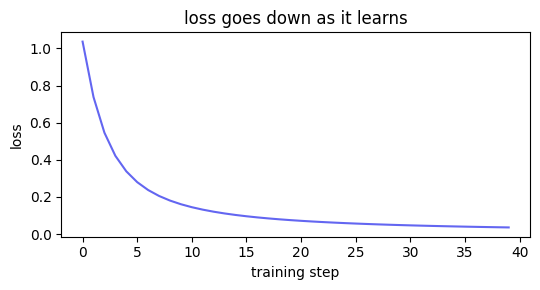

In [5]:
import matplotlib.pyplot as plt
plt.rcParams['axes.unicode_minus'] = False

logits = rng.normal(0, 1, V); losses = []
for _ in range(40):
    p = softmax(logits); losses.append(-np.log(p[target]))
    g = p.copy(); g[target] -= 1; logits -= 0.5 * g

plt.figure(figsize=(5.5, 3))
plt.plot(losses, color='#6366f1')
plt.xlabel('training step'); plt.ylabel('loss'); plt.title('loss goes down as it learns')
plt.tight_layout(); plt.show()

## 6. 직접 해보기 ✏️

정답 확률이 0.5 일 때 크로스 엔트로피 손실 $-\ln(0.5)$ 을 구하세요. (약 0.69)

In [6]:
p_correct = 0.5
loss = -np.log(p_correct)
print('손실:', round(loss, 3))

assert abs(loss - 0.693) < 0.01, '-ln(0.5) 를 계산하세요!'
assert -np.log(1.0) == 0, '정답 확률 1이면 손실 0!'
print('✅ -ln(0.5) ≈ 0.69, -ln(1) = 0')

손실: 0.693
✅ -ln(0.5) ≈ 0.69, -ln(1) = 0


---
무작위 숫자가 **손실을 재고 경사하강으로 줄이기**를 반복하며 똑똑해집니다. 그게 학습입니다.
마지막 챕터(ch12)에서는 이렇게 학습된 모델이 다음 단어를 **어떻게 고르는지**(샘플링) 배웁니다. 🎲